In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA,IncrementalPCA
from sklearn.cluster import KMeans,DBSCAN,OPTICS,AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings("ignore")
try:
  import umap
  HAS_UMAP=True
except ImportError:
  HAS_UMAP=False
  print("Optional: pip install umap-learn")
np.random.seed(42)

In [3]:
import pandas as pd
df = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")
print(df.columns.tolist())          # exact names
print(df.head())                    # preview


['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
  Invoice StockCode  ... Customer ID         Country
0  489434     85048  ...     13085.0  United Kingdom
1  489434    79323P  ...     13085.0  United Kingdom
2  489434    79323W  ...     13085.0  United Kingdom
3  489434     22041  ...     13085.0  United Kingdom
4  489434     21232  ...     13085.0  United Kingdom

[5 rows x 8 columns]


In [4]:
print("Raw shape:", df.shape)

# Rename UCI → standard (handles your exact 3 columns)
df = df.rename(columns={
    "Invoice":     "InvoiceNo",       # Invoice → InvoiceNo
    "Price":       "UnitPrice",       # Price   → UnitPrice
    "Customer ID": "CustomerID",      # space   → no space
})

# Verify
required = ["InvoiceNo", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID"]
missing = [c for c in required if c not in df.columns]
assert not missing, f"Missing: {missing}"

# Clean
df = df.dropna(subset=["CustomerID"])                     # drop rows w/o customer
df["CustomerID"] = df["CustomerID"].astype(int)           # float → int (13085.0 → 13085)
df = df[df["Quantity"] > 0]                               # drop returns
df = df[df["UnitPrice"] > 0]                              # drop £0 prices
df["InvoiceNo"] = df["InvoiceNo"].astype(str)             # cast to str
df = df[~df["InvoiceNo"].str.startswith("C")]             # drop cancellations
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])     # parse dates
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]       # line total
df = df[df["UnitPrice"] <= df["UnitPrice"].quantile(0.99)]  # cap 99th pct

print("Clean shape:", df.shape)
print("Unique customers:", df["CustomerID"].nunique())
print(df.dtypes)

Raw shape: (1067371, 8)
Clean shape: (798381, 9)
Unique customers: 5843
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
Country                object
TotalPrice            float64
dtype: object


In [5]:
# Reference date = 1 day after the last invoice (so Recency ≥ 1)
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)                          # "today"

rfm = df.groupby("CustomerID").agg(
    Recency   = ("InvoiceDate", lambda x: (reference_date - x.max()).days),              # days since last purchase
    Frequency = ("InvoiceNo", "nunique"),                                                # unique invoices (orders)
    Monetary  = ("TotalPrice", "sum"),                                                   # total spend
).reset_index()

rfm = rfm[rfm["Monetary"] > 0]                                                           # drop non-spenders
rfm["AOV"] = rfm["Monetary"] / rfm["Frequency"]                                          # avg order value

print(rfm.describe())                                                                    # sanity check

         CustomerID      Recency    Frequency       Monetary           AOV
count   5843.000000  5843.000000  5843.000000    5843.000000   5843.000000
mean   15319.505220   200.103885     6.253295    2934.015249    379.425989
std     1714.808539   208.590207    12.732031   14348.423643   1200.939020
min    12346.000000     1.000000     1.000000       2.950000      2.950000
25%    13837.500000    25.000000     1.000000     337.580000    177.827500
50%    15320.000000    95.000000     3.000000     862.760000    278.248333
75%    16802.500000   379.000000     7.000000    2241.570000    411.411477
max    18287.000000   739.000000   373.000000  581361.270000  84236.250000


In [6]:
# Log: reduce right-skew from high spenders
rfm["Frequency_log"] = np.log1p(rfm["Frequency"])                                        # log freq
rfm["Monetary_log"]  = np.log1p(rfm["Monetary"])                                         # log spend
rfm["AOV_log"]       = np.log1p(rfm["AOV"])                                              # log AOV

# Standardize: all features weigh equally
X = rfm[["Recency", "Frequency_log", "Monetary_log", "AOV_log"]]                         # feature matrix
X_scaled = StandardScaler().fit_transform(X)                                             # fit + transform

print("Scaled shape:", X_scaled.shape)                                                   # verify

Scaled shape: (5843, 4)


In [7]:
# PCA to 95% variance
pca  = PCA(n_components=0.95, random_state=42)                                           # keep 95% info
X_pca = pca.fit_transform(X_scaled)                                                      # fit
print("PCA kept:", X_pca.shape[1], "components")                                         # how many?
print("Variance explained:", pca.explained_variance_ratio_)                              # per-PC

# 2D PCA for plotting
X_pca2 = PCA(n_components=2, random_state=42).fit_transform(X_scaled)                    # 2D

# Incremental PCA — same result, batched
X_ipca = IncrementalPCA(n_components=2, batch_size=1000).fit_transform(X_scaled)         # batched

PCA kept: 3 components
Variance explained: [0.6310042  0.23023893 0.13798593]


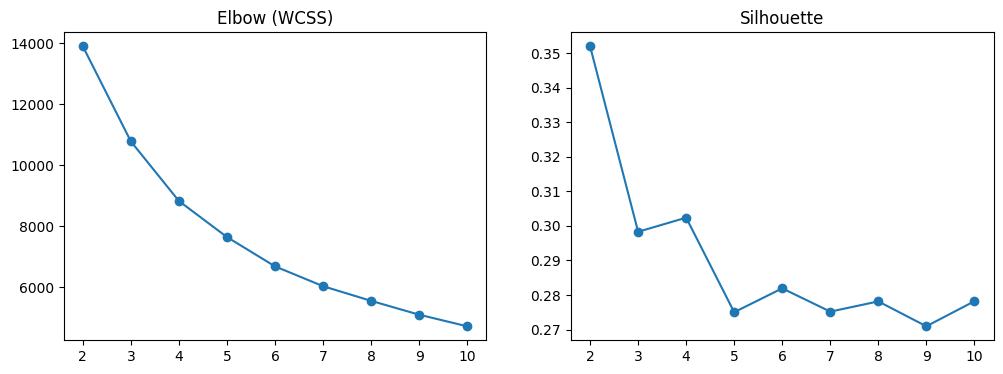

Best k: 2
kmeans_cluster
0    3024
1    2819
Name: count, dtype: int64


In [8]:
# Loop k = 2..10, record WCSS and silhouette
inertias, sils = [], []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)                                # init
    labels = km.fit_predict(X_scaled)                                                    # fit
    inertias.append(km.inertia_)                                                         # WCSS
    sils.append(silhouette_score(X_scaled, labels))                                      # silhouette

# Plot both
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(2, 11), inertias, marker="o"); ax[0].set_title("Elbow (WCSS)")
ax[1].plot(range(2, 11), sils, marker="o");     ax[1].set_title("Silhouette")
plt.show()

best_k = 2 + int(np.argmax(sils))                                                        # best k
print("Best k:", best_k)                                                                 # print

# Fit final model
kmeans = KMeans(n_clusters=best_k, n_init=10, random_state=42)                           # init
rfm["kmeans_cluster"] = kmeans.fit_predict(X_scaled)                                     # assign
print(rfm["kmeans_cluster"].value_counts())                                              # sizes

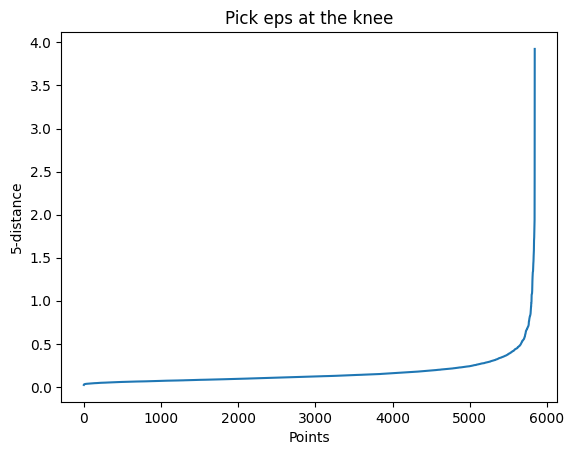

dbscan_cluster
-1      57
 0    5784
 1       2
Name: count, dtype: int64
optics_cluster
-1      3236
 0         7
 1         6
 2         5
 3         5
        ... 
 325       5
 326      10
 327       7
 328       5
 329       5
Name: count, Length: 331, dtype: int64


In [9]:
# k-distance plot to pick eps
nbrs = NearestNeighbors(n_neighbors=5).fit(X_scaled)                                     # build index
distances, _ = nbrs.kneighbors(X_scaled)                                                 # query
plt.plot(np.sort(distances[:, -1]))                                                      # plot kth-dist
plt.xlabel("Points"); plt.ylabel("5-distance")
plt.title("Pick eps at the knee"); plt.show()                                            # visually pick

# DBSCAN
rfm["dbscan_cluster"] = DBSCAN(eps=0.7, min_samples=5).fit_predict(X_scaled)             # fit
print(rfm["dbscan_cluster"].value_counts().sort_index())                                 # -1 = noise

# OPTICS
rfm["optics_cluster"] = OPTICS(min_samples=5).fit_predict(X_scaled)                      # fit
print(rfm["optics_cluster"].value_counts().sort_index())                                 # counts

Hierarchical silhouette: 0.31138062690093216


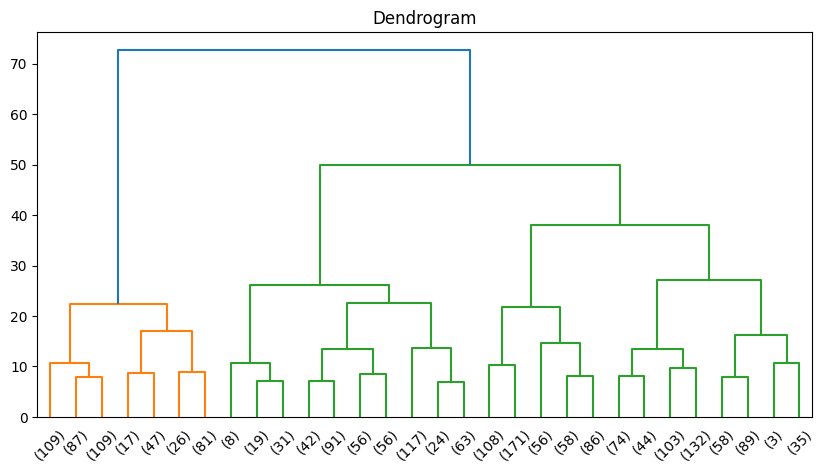

In [10]:
# Sample 2000 rows (Hierarchical is O(n²))
idx = np.random.choice(len(X_scaled), 2000, replace=False)                               # indices
X_hc = X_scaled[idx]                                                                     # sample

hc = AgglomerativeClustering(n_clusters=best_k, linkage="ward")                          # Ward
hc_labels = hc.fit_predict(X_hc)                                                         # fit
print("Hierarchical silhouette:", silhouette_score(X_hc, hc_labels))                     # score

# Dendrogram
plt.figure(figsize=(10, 5))                                                              # figure
dendrogram(linkage(X_hc, method="ward"), truncate_mode="lastp", p=30)                    # draw
plt.title("Dendrogram"); plt.show()                                                      # show

In [11]:
iso = IsolationForest(n_estimators=200, contamination=0.02, random_state=42)             # 2% anomalies
rfm["anomaly"] = iso.fit_predict(X_scaled)                                               # -1 = anomaly
print(rfm["anomaly"].value_counts())                                                     # count

anomaly
 1    5726
-1     117
Name: count, dtype: int64


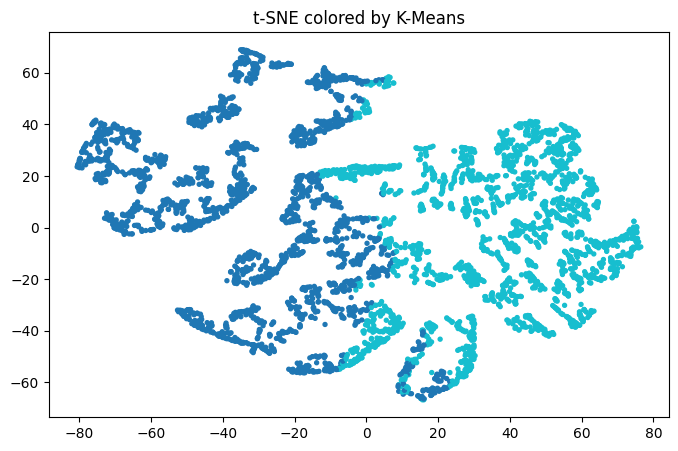

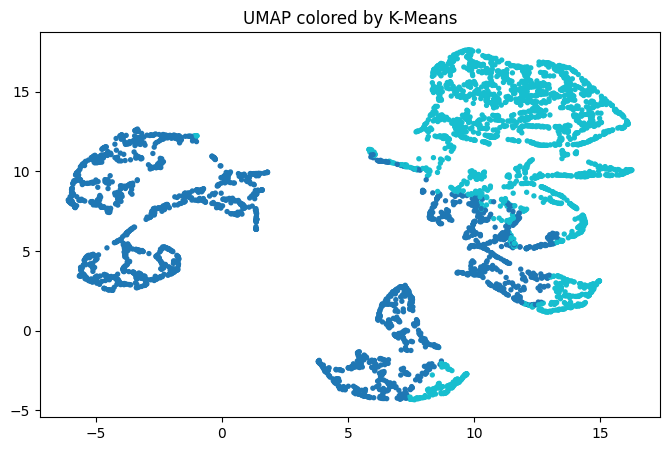

In [12]:
# Sample 5000 (t-SNE slow on 4k+ customers)
idx = np.random.choice(len(X_scaled), min(5000, len(X_scaled)), replace=False)           # indices
X_s = X_scaled[idx]                                                                      # sample
y_s = rfm.iloc[idx]["kmeans_cluster"].values                                             # labels

# t-SNE
X_tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=42).fit_transform(X_s)
plt.figure(figsize=(8, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y_s, s=8, cmap="tab10")
plt.title("t-SNE colored by K-Means"); plt.show()

# UMAP (faster, similar result)
if HAS_UMAP:
    X_umap = umap.UMAP(n_components=2, random_state=42).fit_transform(X_s)               # fit
    plt.figure(figsize=(8, 5))
    plt.scatter(X_umap[:, 0], X_umap[:, 1], c=y_s, s=8, cmap="tab10")                    # scatter
    plt.title("UMAP colored by K-Means"); plt.show()

In [13]:
# Cluster summary
profile = rfm.groupby("kmeans_cluster").agg(
    n_customers  = ("CustomerID", "count"),                                              # count
    avg_recency  = ("Recency", "mean"),                                                  # recency
    avg_freq     = ("Frequency", "mean"),                                                # freq
    avg_monetary = ("Monetary", "mean"),                                                 # spend
    avg_aov      = ("AOV", "mean"),                                                      # AOV
).reset_index()

# Assign personas — adjust thresholds after seeing real numbers
def persona(row):
    if row["avg_monetary"] > 5000 and row["avg_freq"] > 10:                              # top spenders
        return "VIP loyal"
    elif row["avg_recency"] < 30 and row["avg_monetary"] > 500:                          # recent buyers
        return "Recent high-value"
    elif row["avg_monetary"] < 300:                                                      # low-value
        return "Low-value / churn risk"
    else:
        return "Regular"

profile["persona"] = profile.apply(persona, axis=1)                                      # apply
print(profile[["kmeans_cluster", "persona", "n_customers", "avg_monetary"]])

# Save results
import os
os.makedirs("outputs", exist_ok=True)                                                    # create folder
rfm.to_csv("outputs/rfm_clustered.csv", index=False)                                     # save RFM
profile.to_csv("outputs/cluster_personas.csv", index=False)                              # save profiles
print("Saved to:", os.path.abspath("outputs"))                                           # show path

   kmeans_cluster    persona  n_customers  avg_monetary
0               0    Regular         3024    432.205966
1               1  VIP loyal         2819   5617.758161
Saved to: /content/outputs
